# 19. Fluxo de MLOps para o preço de uma commodity

**Objetivo e requisitos.** Levar um modelo de previsão do experimento à operação e mantê-lo: treinar, registrar e promover; prever o preço do dia seguinte todos os dias, registrando previsões e observações; monitorar o erro contra a referência; e retreinar por agenda ou por alerta, com um portão que só troca o modelo de produção quando o desafiante não é pior. Tudo fica num banco SQLite (`ExperimentStore`). A série é o preço diário sintético de uma saca de café, com um choque de oferta. Extras `stats` e `plot`; nenhum download.

In [1]:
import shutil
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment, ExperimentStore, save_model
from autohybts.datasets import get_data

warnings.filterwarnings("ignore")
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc3


## 1. Dados e protocolo

`commodity_price_daily` tem tendência lenta, ciclo anual de safra e choques persistentes; no dia 821 um choque de oferta sobe o nível em cerca de 20 % e dobra a volatilidade. O modelo entra em produção no dia 600 e prevê um passo por vez (protocolo B, sem reajuste entre os dias). As regras de operação:

- **portão:** os últimos 60 dias de cada treino ficam selados; o desafiante só substitui a produção se o seu erro nesses dias não for maior que o erro real da produção nos mesmos dias;
- **monitoramento:** MAE móvel de 30 dias; alerta quando passa de 1,5 vez o MAE de referência do modelo (o do teste selado);
- **retreino:** por alerta (no máximo um a cada 60 dias) ou por agenda, a cada 120 dias.

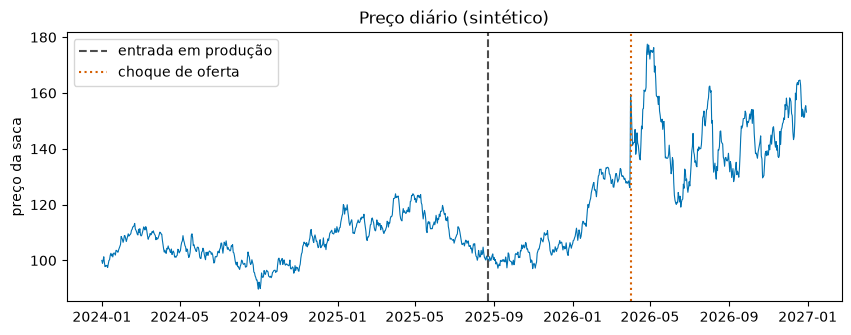

In [2]:
price = get_data("commodity_price_daily")
NAME, DEPLOY, GATE, WINDOW, THRESHOLD, SCHEDULE = "preco_cafe", 600, 60, 30, 1.5, 120
SHOCK = int(len(price) * 0.75)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(price.index, price.to_numpy(), linewidth=0.8, color="#0072B2")
ax.axvline(price.index[DEPLOY], color="0.3", linestyle="--", label="entrada em produção")
ax.axvline(price.index[SHOCK], color="#D55E00", linestyle=":", label="choque de oferta")
ax.set(ylabel="preço da saca", title="Preço diário (sintético)")
ax.legend()
plt.show()

## 2. Treino, registro e promoção

`train` é o pipeline de treino: compara os modelos com os últimos 60 dias selados, finaliza o campeão, lê o teste selado uma vez (o MAE vira a referência do monitoramento), registra o experimento no banco, salva o artefato e o registra como `candidate`. O primeiro modelo vai direto para produção.

In [3]:
folder = Path("artifacts/mlops")
shutil.rmtree(folder, ignore_errors=True)
store = ExperimentStore(folder / "mlops.db")
SETTINGS = {
    "fh": 1,
    "variant": "B",
    "test_size": GATE,
    "session_id": 42,
    "budget": "smoke",
    "base_models": ["naive", "linear", "knn", "exponential_smoothing"],
    "correctors": ["linear", "knn"],
}


def train(history, label):
    exp = AutoHybridExperiment(**SETTINGS).fit(history)
    final = exp.finalize_model(exp.compare_models().best)
    mae = float(exp.evaluate_external(final).metrics["MAE"].iloc[0])
    run_id = store.log(exp, name=label, models=[final], values=True)
    path = save_model(final, folder / "modelos" / final.model_id[:12])
    store.register_model(final, path, name=NAME, run_id=run_id, reference_mae=mae)
    return final, mae, run_id


first, mae, _ = train(price.iloc[:DEPLOY], "treino-inicial")
store.promote(first.model_id, reason="primeiro modelo")
store.registry(NAME)[["label", "stage", "reference_mae", "registered_utc"]]

,label,stage,reference_mae,registered_utc
0,naive,production,1.001,2026-10-14T12:19:39.120606+00:00


## 3. Operação diária

O serviço carrega o modelo de produção pelo registro (com `trusted=True` e o SHA-256 registrado) e o atualiza com as observações posteriores ao seu treino, sem reajustar. A cada dia: prevê o dia seguinte, registra a previsão, recebe o preço observado, registra a observação e consulta o monitoramento. Quando um retreino acontece, o portão compara, nos mesmos 60 dias, o erro do desafiante no seu teste selado com o erro real que a produção registrou.

In [4]:
def serve(t):
    """Production model from the registry, updated with the observations up to day t."""
    model = store.load(NAME, trusted=True)
    start = price.index.get_loc(model.last_observation) + 1
    return model.update_state(price.iloc[start : t + 1]).stream()


SERIES_ID = first.history.series_id
stream, events, last_retrain = serve(DEPLOY - 1), [], DEPLOY
for t in range(DEPLOY, len(price)):
    ticket = stream.predict_next()
    model_id = stream.model.model_id
    store.log_forecasts(
        model_id,
        pd.DataFrame(
            {
                "timestamp": [ticket.timestamp],
                "origin": [ticket.origin],
                "y_pred": [ticket.prediction],
            }
        ),
    )
    stream.observe(price.iloc[t])
    store.log_actuals(SERIES_ID, price.iloc[t : t + 1])
    alert = bool(store.monitor(model_id, window=WINDOW, threshold=THRESHOLD).alert.iloc[-1])
    if not ((alert and t - last_retrain >= GATE) or t - last_retrain >= SCHEDULE):
        continue
    reason = "alerta" if alert else "agenda"
    challenger, challenger_mae, run_id = train(
        price.iloc[: t + 1], f"retreino-{price.index[t].date()}"
    )
    live_mae = store.query(
        """
        SELECT AVG(ABS(a.y_true - f.y_pred)) AS mae
        FROM forecasts f JOIN actuals a USING (series_id, timestamp)
        WHERE f.model_id = ? AND f.timestamp IN (SELECT timestamp FROM predictions WHERE run_id = ?)
        """,
        (model_id, run_id),
    ).mae[0]
    promoted = challenger_mae <= live_mae
    if promoted:
        store.promote(
            challenger.model_id, reason=f"{reason}: MAE {challenger_mae:.3f} <= {live_mae:.3f}"
        )
        stream = serve(t)
    events.append(
        {
            "dia": price.index[t].date(),
            "motivo": reason,
            "desafiante": challenger.spec.label,
            "mae_desafiante": round(challenger_mae, 3),
            "mae_producao": round(live_mae, 3),
            "promovido": promoted,
        }
    )
    last_retrain = t
pd.DataFrame(events)

,dia,motivo,desafiante,mae_desafiante,mae_producao,promovido
0,2025-12-21,agenda,naive,0.956,0.956,True
1,2026-04-01,alerta,naive,1.584,1.584,True
2,2026-06-02,alerta,exponential_smoothing(season_length=7),2.859,2.862,True
3,2026-09-30,agenda,naive,2.583,2.577,False


## 4. Monitoramento

O registro guarda o estágio de cada modelo e o histórico de trocas; as previsões e as observações permitem reconstruir o erro real de cada modelo no período em que esteve em produção.

In [5]:
store.query(
    """
    SELECT h.at, r.label, h.stage, h.reason
    FROM stage_history h JOIN registry r USING (model_id)
    WHERE h.stage <> 'candidate'
    ORDER BY h.at, h.stage
    """
)

,at,label,stage,reason
0,2026-10-14T12:19:39.124946+00:00,naive,production,primeiro modelo
1,2026-10-14T12:19:47.045971+00:00,naive,archived,substituído por ea909cf8eb5f
2,2026-10-14T12:19:47.045971+00:00,naive,production,agenda: MAE 0.956 <= 0.956
3,2026-10-14T12:19:52.464420+00:00,naive,archived,substituído por dda88c3e0919
4,2026-10-14T12:19:52.464420+00:00,naive,production,alerta: MAE 1.584 <= 1.584
5,2026-10-14T12:20:11.818639+00:00,naive,archived,substituído por d4b8db2509be
6,2026-10-14T12:20:11.818639+00:00,exponential_smoothing(season_length=7),production,alerta: MAE 2.859 <= 2.862


In [6]:
live = store.query(
    """
    SELECT r.label, MIN(f.timestamp) AS inicio, MAX(f.timestamp) AS fim, COUNT(*) AS dias,
           ROUND(AVG(ABS(a.y_true - f.y_pred)), 3) AS mae_real,
           ROUND(r.reference_mae, 3) AS mae_referencia
    FROM forecasts f
    JOIN actuals a USING (series_id, timestamp)
    JOIN registry r USING (model_id)
    GROUP BY f.model_id
    ORDER BY inicio
    """
)
live

,label,inicio,fim,dias,mae_real,mae_referencia
0,naive,2025-08-23T00:00:00,2025-12-21T00:00:00,121,0.989,1.001
1,naive,2025-12-22T00:00:00,2026-04-01T00:00:00,101,1.488,0.956
2,naive,2026-04-02T00:00:00,2026-06-02T00:00:00,62,2.965,1.584
3,exponential_smoothing(season_length=7),2026-06-03T00:00:00,2026-12-30T00:00:00,211,2.515,2.859


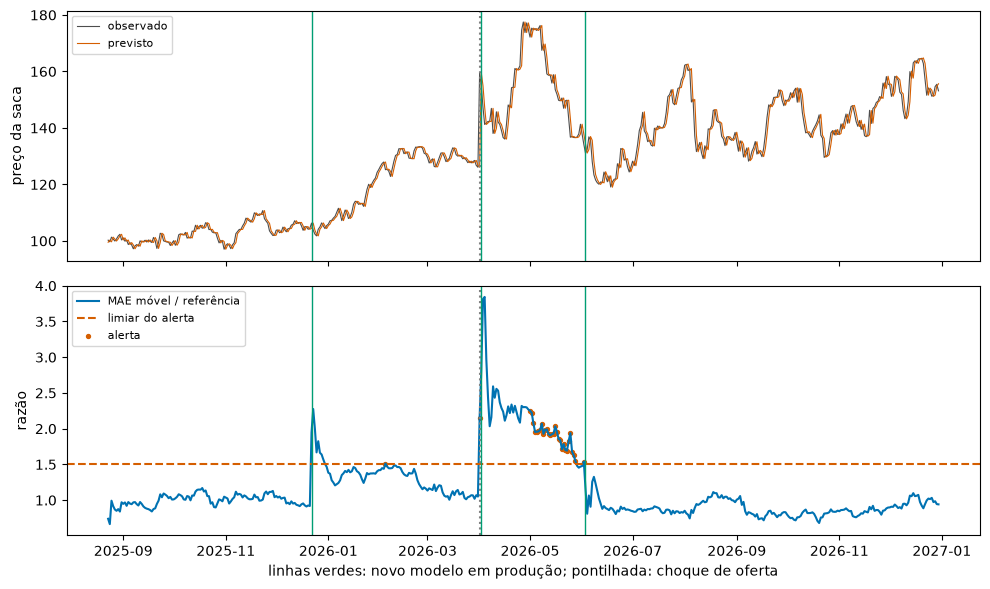

In [7]:
status = pd.concat(
    [
        store.monitor(model_id, window=WINDOW, threshold=THRESHOLD).assign(model_id=model_id)
        for model_id in store.query("SELECT DISTINCT model_id FROM forecasts").model_id
    ]
).sort_values("timestamp")
status["timestamp"] = pd.to_datetime(status.timestamp)
promotions = store.query(
    "SELECT MIN(f.timestamp) AS inicio FROM forecasts f GROUP BY f.model_id ORDER BY inicio"
).inicio.iloc[1:]

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
operation = price.iloc[DEPLOY:]
axes[0].plot(operation.index, operation.to_numpy(), color="0.3", linewidth=0.8, label="observado")
axes[0].plot(status.timestamp, status.y_pred, color="#D55E00", linewidth=0.8, label="previsto")
axes[0].set(ylabel="preço da saca")
axes[1].plot(status.timestamp, status.ratio, color="#0072B2", label="MAE móvel / referência")
axes[1].axhline(THRESHOLD, color="#D55E00", linestyle="--", label="limiar do alerta")
alerts = status[status.alert]
axes[1].scatter(alerts.timestamp, alerts.ratio, s=8, color="#D55E00", label="alerta")
axes[1].set(ylabel="razão")
for ax in axes:
    ax.axvline(price.index[SHOCK], color="0.5", linestyle=":")
    for day in pd.to_datetime(promotions):
        ax.axvline(day, color="#009E73", linewidth=1)
    ax.legend(fontsize=8, loc="upper left")
axes[1].set_xlabel("linhas verdes: novo modelo em produção; pontilhada: choque de oferta")
fig.tight_layout()
plt.show()

## 5. Avaliação da operação

O teste final da operação é comparar as previsões que de fato foram usadas com uma referência simples, calculada no próprio banco: a persistência (o preço de ontem como previsão de hoje), obtida com `LAG` sobre as observações.

In [8]:
store.query(
    """
    WITH observed AS (
        SELECT timestamp, y_true, LAG(y_true) OVER (ORDER BY timestamp) AS persistencia
        FROM actuals
    )
    SELECT CASE WHEN o.timestamp < ? THEN 'antes do choque' ELSE 'depois do choque' END AS periodo,
           COUNT(*) AS dias,
           ROUND(AVG(ABS(o.y_true - f.y_pred)), 3) AS mae_operacao,
           ROUND(AVG(ABS(o.y_true - o.persistencia)), 3) AS mae_persistencia
    FROM forecasts f JOIN observed o USING (timestamp)
    WHERE o.persistencia IS NOT NULL
    GROUP BY periodo
    ORDER BY periodo
    """,
    (price.index[SHOCK].isoformat(),),
)

,periodo,dias,mae_operacao,mae_persistencia
0,antes do choque,220,1.072,1.072
1,depois do choque,274,2.729,2.727


## 6. Leitura

- **Primeiro modelo.** A seleção escolheu a persistência (`naive`), com MAE de referência 1,001 no teste selado. Num preço que se comporta quase como um passeio aleatório, isso é esperado: nenhum modelo nem corretor superou o preço de ontem com folga suficiente para passar a regra de aceite.
- **Operação.** Foram 495 dias de previsões, registradas uma a uma com as observações. Houve quatro retreinos: dois por agenda (21/12/2025 e 30/09/2026) e dois por alerta (01/04/2026 e 02/06/2026). Três desafiantes passaram o portão e um foi recusado, porque o seu MAE nos 60 dias selados (2,583) ficou acima do erro real da produção nas mesmas datas (2,577). Um alerta isolado em 04/02/2026 não gerou retreino, por estar a menos de 60 dias do anterior.
- **Choque de oferta.** O alerta disparou no próprio dia do choque (01/04/2026): o salto de preço sozinho levou o MAE móvel acima de 1,5 vez a referência. O modelo treinado nesse dia ainda tinha uma referência do regime antigo (1,584), e os alertas voltaram de 01/05 a 02/06. Nesse período o retreino esperou a regra de no máximo um a cada 60 dias. Só o retreino de 02/06, com 60 dias do regime novo no teste, trouxe uma referência coerente (2,859): o ETS que entrou não teve nenhum alerta até o fim.
- **Erro real × referência.** O primeiro modelo ficou perto da referência (0,989 contra 1,001). Os dois seguintes atravessaram o choque com referências do regime antigo e ficaram bem acima delas (1,488 contra 0,956 e 2,965 contra 1,584). O ETS ficou abaixo da sua (2,515 contra 2,859). O monitoramento mede exatamente essa distância.
- **Contra a persistência.** As previsões usadas na operação tiveram MAE igual ao da persistência antes do choque (1,072) e praticamente igual depois (2,729 contra 2,727). O valor do fluxo, nesta série, não está em prever melhor que o preço de ontem: está em perceber a mudança de regime, atualizar a referência e deixar cada troca registrada e auditável.
- **Rastro.** O banco guarda os experimentos de cada treino, o registro dos modelos com o SHA-256 dos artefatos, o histórico de estágios com os motivos e todas as previsões e observações: qualquer pergunta sobre a operação pode ser respondida depois, com SQL.